***
# __EINLEITUNG__
Dieses Projekt beschäftigt sich mit dem Datensatz "Road Accident dataset". Er enthält Daten zu Autounfällen, wie unter anderem deren Datierung, verschiedene Umstände wie Lichtverhältnisse und Details zur Unfallstelle und dem Wetter und den Schweregrad des Unfalls klassifiziert nach "Slight", "Serious" und "Fatal".

Ziel des Projekts ist es, deskriptiv zu ermitteln, unter welchen zeitlichen, infrastrukturellen und umweltbedingten Umständen (u. a. Tageszeit, Wochentag, Straßentyp, Ortslage, Licht- und Wetterverhältnisse) Verkehrsunfälle absolut am häufigsten auftreten und welche dieser Merkmale die stärksten statistischen Zusammenhänge mit dem Schweregrad der Unfälle aufweisen.

Um einen ersten Überblick zum Thema zu erhalten wurden die Folgenden Publikationen genutzt: 

- Vaiyapuri & Gupta (2021): "Traffic accident severity prediction and cognitive analysis using deep learning"
    - **Fragestellung:** Wie 

Zunächst wird ein grober Überblick über den Datensatz gegeben. Dabei werden die enthaltenen Variablen hinsichtlich ihrer Skalenniveaus eingeordnet und kurz beschrieben.

Bevor die eigentliche Analyse beginnt, werden die Dateneinträge genauer untersucht, um mögliche ungültige Werte zu identifizieren und festzustellen, ob bestimmte Variablen für die weitere Analyse nicht relevant sind.
***

***
# __ERSTER BLICK AUF DEN DATENSATZ__

#### <u>Import der zur Datenanalyse benötigten Module</u>

In [ ]:
#Import der zur Datenanalyse benötigten Module
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

#Erstellung des Dataframes aus der CSV Datei
df = pd.read_csv("Road_Accident_Data.csv")

#### <u>Variablen, Skalenniveaus und Beschreibungen</u>


Um einen Überblick über den Datensatz zu erhalten, werden zunächst die enthaltenen Variablen betrachtet. Dazu werden diese den entprechenden Skalenniveaus zugeordnet und kurz beschrieben.

| Variable | Skalenniveau | Beschreibung |
| --- | --- | --- |
| Accident_Index | Nominal | Eindeutige ID des Unfalls |
| Accident_Date | Nominal | Datum, an dem der Unfall stattgefunden hat |
| Month | Nominal | Monat, in dem der Unfall stattgefunden hat (redundant) |
| Day_of_Week | Nominal | Wochentag, an dem der Unfall stattgefunden hat |
| Year | Nominal | Jahr, in dem der Unfall stattgefunden hat (redundant) |
| Junction_Control | Ordinal | Art der Verkehrssteuerung am Unfallort |
| Junction_Detail | Nominal | Details zur Unfallstelle |
| Accident_Severity | Ordinal | Schweregrad des Unfalls (Slight/Serious/Fatal)|
| Latitude | Nominal | Breitengrad der Unfallstelle |
| Light_Conditions | Ordinal | Lichtverhältnisse während des Unfalls |
| Local_Authority_(District) | Nominal | Lokale Behörde am Unfallort |
| Carriageway_Hazards | Nominal | Art des Hindernis auf der Straße |
| Longitude | Nominal | Längegrad der Unfallstelle |
| Number_of_Casualties | Kardinal | Anzahl der Verletzten |
| Number_of_Vehicles | Kardinal | Anzahl der beteiligten Fahrzeuge |
| Police_Force | Nominal | Zuständige Polizeibehörde |
| Road_Surface_Conditions | Ordinal | Zustand der Straße (Nass/Trocken/...) |
| Road_Type | Nominal | Art der Straße |
| Speed_limit | Kardinal | Geschwindikeitsbegrenzung an der Unfallstelle |
| Time | Nominal | Zeit des Unfalls |
| Urban_or_Rural_Area | Nominal | Ländlich/Städtisch gelegen |
| Weather_Conditions | Nominal | Wetterbedingungen zur Zeit des Unfalls |
| Vehicle_Type | Nominal | Art der beteiligten Fahrzeuge |


#### <u>Informationen über den Datensatz</u>

Ausgabe der ersten fünf und letzten fünf Zeilen des Datensatzes:

In [ ]:
#Ausgabe der obersten fünf Zeilen
df.head()

,Accident_Index,Accident Date,Month,Day_of_Week,Year,Junction_Control,Junction_Detail,Accident_Severity,Latitude,Light_Conditions,...,Number_of_Casualties,Number_of_Vehicles,Police_Force,Road_Surface_Conditions,Road_Type,Speed_limit,Time,Urban_or_Rural_Area,Weather_Conditions,Vehicle_Type
0,200901BS70001,1/1/2021,Jan,Thursday,2021,Give way or uncontrolled,T or staggered junction,Serious,51.512273,Daylight,...,1,2,Metropolitan Police,Dry,One way street,30,15:11,Urban,Fine no high winds,Car
1,200901BS70002,1/5/2021,Jan,Monday,2021,Give way or uncontrolled,Crossroads,Serious,51.514399,Daylight,...,11,2,Metropolitan Police,Wet or damp,Single carriageway,30,10:59,Urban,Fine no high winds,Taxi/Private hire car
2,200901BS70003,1/4/2021,Jan,Sunday,2021,Give way or uncontrolled,T or staggered junction,Slight,51.486668,Daylight,...,1,2,Metropolitan Police,Dry,Single carriageway,30,14:19,Urban,Fine no high winds,Taxi/Private hire car
3,200901BS70004,1/5/2021,Jan,Monday,2021,Auto traffic signal,T or staggered junction,Serious,51.507804,Daylight,...,1,2,Metropolitan Police,Frost or ice,Single carriageway,30,8:10,Urban,Other,Motorcycle over 500cc
4,200901BS70005,1/6/2021,Jan,Tuesday,2021,Auto traffic signal,Crossroads,Serious,51.482076,Darkness - lights lit,...,1,2,Metropolitan Police,Dry,Single carriageway,30,17:25,Urban,Fine no high winds,Car


In [ ]:
#Ausgabe der untersten fünf Zeilen
df.tail()

,Accident_Index,Accident Date,Month,Day_of_Week,Year,Junction_Control,Junction_Detail,Accident_Severity,Latitude,Light_Conditions,...,Number_of_Casualties,Number_of_Vehicles,Police_Force,Road_Surface_Conditions,Road_Type,Speed_limit,Time,Urban_or_Rural_Area,Weather_Conditions,Vehicle_Type
307968,201091NM01760,2/18/2022,Feb,Thursday,2022,Data missing or out of range,Not at junction or within 20 metres,Slight,57.374005,Daylight,...,2,1,Northern,Dry,Single carriageway,60,7:00,Rural,Fine no high winds,Car
307969,201091NM01881,2/21/2022,Feb,Sunday,2022,Data missing or out of range,Not at junction or within 20 metres,Slight,57.232273,Darkness - no lighting,...,1,1,Northern,Frost or ice,Single carriageway,60,3:00,Rural,Fine no high winds,Car
307970,201091NM01935,2/23/2022,Feb,Tuesday,2022,Give way or uncontrolled,T or staggered junction,Slight,57.585044,Daylight,...,1,3,Northern,Frost or ice,Single carriageway,30,9:38,Rural,Fine no high winds,Car
307971,201091NM01964,2/23/2022,Feb,Tuesday,2022,Give way or uncontrolled,T or staggered junction,Serious,57.214898,Darkness - no lighting,...,1,2,Northern,Wet or damp,Single carriageway,60,18:25,Rural,Fine no high winds,Motorcycle over 500cc
307972,201091NM02142,2/28/2022,Feb,Sunday,2022,Give way or uncontrolled,T or staggered junction,Serious,57.575210,Daylight,...,1,1,Northern,Wet or damp,Dual carriageway,60,15:45,Rural,Snowing no high winds,Car


<br>
Als nächstes werden allgemeine Informationen über den Datensatz untersucht:

In [ ]:
#Informationen über den Datensatz ausgeben
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 307973 entries, 0 to 307972
Data columns (total 23 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   Accident_Index              307973 non-null  str    
 1   Accident Date               307973 non-null  str    
 2   Month                       307973 non-null  str    
 3   Day_of_Week                 307973 non-null  str    
 4   Year                        307973 non-null  int64  
 5   Junction_Control            307973 non-null  str    
 6   Junction_Detail             307973 non-null  str    
 7   Accident_Severity           307973 non-null  str    
 8   Latitude                    307973 non-null  float64
 9   Light_Conditions            307973 non-null  str    
 10  Local_Authority_(District)  307973 non-null  str    
 11  Carriageway_Hazards         5424 non-null    str    
 12  Longitude                   307973 non-null  float64
 13  Number_of_Casualties     

Der Datensatz hat 23 Spalten und 307973 Zeilen. Die Spalten "Carriageway_Hazards", "Road_Surface_Conditions", "Road_Type", "Time" und "Weather_Conditions" enthalten jeweils Null-Werte. 

Im Fall der "Carriageway_Hazards" ist der Grund, dass Pandas Zeilen die mit "None" gefüllt sind (keine Hindernisse vorhanden) als Null interpretiert. Da "None" aber ein Aussagekräftiger Wert ist, haben wir uns dazu entschieden, leere Werte dieser Spalte durch den Wert "No Hazards" zu ersetzen (siehe unten)

In den anderen Spalten gibt es keine Erklärung für leere Werte. Um Auswertungen nicht zu verfälschen, werden diese Werte nicht ersetzt, es wurden allerdings auch nicht die entsprechenden Elemente gelöscht, um ihre anderen Werte in der Auswertung berücksichtigen zu können.

Um ein besseres Verständnis und ein erstes Bild der Werteverteilung im Datensatz zu erhalten wurde im Folgenden eine Auswertung mithilfe von pandas.dataframe.describe() erstellt:

<br>

In [ ]:
#Ersetzen der leeren Werte in "Carriageway_Hazards"
df["Carriageway_Hazards"] = df["Carriageway_Hazards"].fillna("No Hazards")

In [ ]:
#Auswertung der Werteverteilung der kardinal skalierten Attribute
print(df.describe())

                Year       Latitude      Longitude  Number_of_Casualties  \
count  307973.000000  307973.000000  307973.000000         307973.000000   
mean     2021.468934      52.487005      -1.368884              1.356882   
std         0.499035       1.339011       1.356092              0.815857   
min      2021.000000      49.914488      -7.516225              1.000000   
25%      2021.000000      51.485248      -2.247937              1.000000   
50%      2021.000000      52.225943      -1.349258              1.000000   
75%      2022.000000      53.415517      -0.206810              1.000000   
max      2022.000000      60.598055       1.759398             48.000000   

       Number_of_Vehicles    Speed_limit  
count       307973.000000  307973.000000  
mean             1.829063      38.866037  
std              0.710477      14.032933  
min              1.000000      10.000000  
25%              1.000000      30.000000  
50%              2.000000      30.000000  
75%           

Es fällt auf, dass gerade "Number_of_Casualties" und "Number_of_Vehicles" trotz einer geringen Standardabweichung starke Ausreißer nach oben aufweisen. 

Im Fall von "Number_of_Casualties" gab es im arithmetischen Mittel ca. 1.36 Verletzte pro Unfall mit einer Standardabweichung von ca. 0.8 aber einem Minimum, Meridian und oberem Quartil von 1. Dies deutet darauf hin, dass wenige starke Ausreißer das arithmetische Mittel erhöhen. Diese Vermutung wird auch durch das Maximum von 48 Verletzten unterstützt.

Bei "Number of Vehicles" verhält es sich ähnlich, allerdings nicht ganz so stark. Das Arithmetische Mittel beträgt ca. 1.8 Fahrzeuge mit einer Standardabweichung von ca. 0.7., allerdings beträgt das obere Quartil nur 2 Fahrzeuge, was zusammen mit dem Maximalwert von 32 auf starke Ausreißer hindeutet.


Damit man gut mit dem Datensatz arbeiten kann, lohnt es sich die einzelnen Spalten genauer anzuschauen um zu überprüfen, ob alle Spalten wirklich Informationen enthalten, die für spätere Analysen wichtig sind.

Dazu wird überprüft, wie viele verschiedene Werte die einzelnen Spalten beeinhalten:

In [ ]:
#Speichern aller Spalten in eine Liste über die später iteriert wird
spalten = df.columns.to_numpy()

#Interation über alle Spalten um die Anzahl unterschiedlicher Werte auszugeben
for spalte in spalten:
    print(f"• {spalte} hat {df[spalte].nunique()} unterschiedliche Werte")

• Accident_Index hat 197644 unterschiedliche Werte
• Accident Date hat 730 unterschiedliche Werte
• Month hat 12 unterschiedliche Werte
• Day_of_Week hat 7 unterschiedliche Werte
• Year hat 2 unterschiedliche Werte
• Junction_Control hat 6 unterschiedliche Werte
• Junction_Detail hat 9 unterschiedliche Werte
• Accident_Severity hat 3 unterschiedliche Werte
• Latitude hat 264362 unterschiedliche Werte
• Light_Conditions hat 5 unterschiedliche Werte
• Local_Authority_(District) hat 422 unterschiedliche Werte
• Carriageway_Hazards hat 6 unterschiedliche Werte
• Longitude hat 269856 unterschiedliche Werte
• Number_of_Casualties hat 28 unterschiedliche Werte
• Number_of_Vehicles hat 17 unterschiedliche Werte
• Police_Force hat 51 unterschiedliche Werte
• Road_Surface_Conditions hat 5 unterschiedliche Werte
• Road_Type hat 5 unterschiedliche Werte
• Speed_limit hat 8 unterschiedliche Werte
• Time hat 1439 unterschiedliche Werte
• Urban_or_Rural_Area hat 2 unterschiedliche Werte
• Weather_Con

<Axes: xlabel='Number_of_Casualties', ylabel='Accident_Severity'>

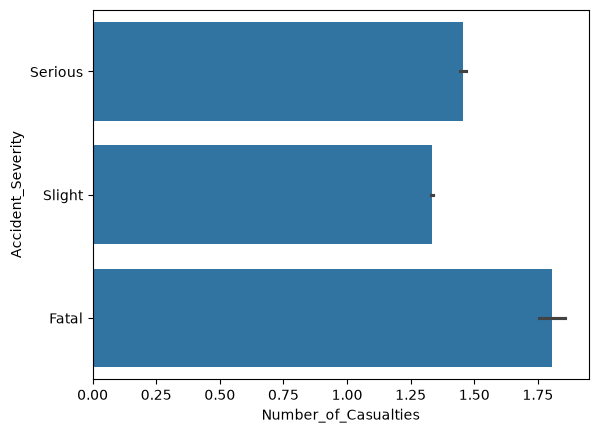

In [ ]:
#Erstellung eines Pair-Grids für den Datensatz
sns.barplot(x = "Number_of_Casualties", y = "Accident_Severity", data= df, orient = "h")

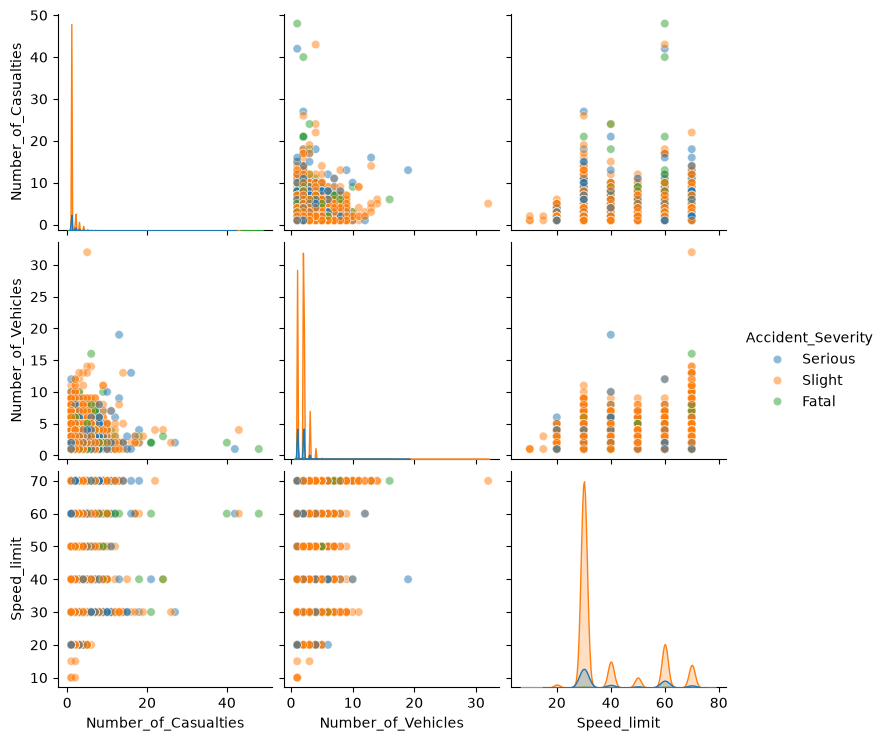

In [ ]:
# 2. Sinnvolle numerische Spalten auswählen
cols = ["Number_of_Casualties", "Number_of_Vehicles", "Speed_limit"]

g = sns.pairplot(
    df,
    vars=cols,
    hue="Accident_Severity",
    plot_kws={"alpha": 0.5},  # Transparenz gegen Überlagerung
)
plt.show()

TypeError: The x variable is categorical, but one of ['numeric', 'datetime'] is required

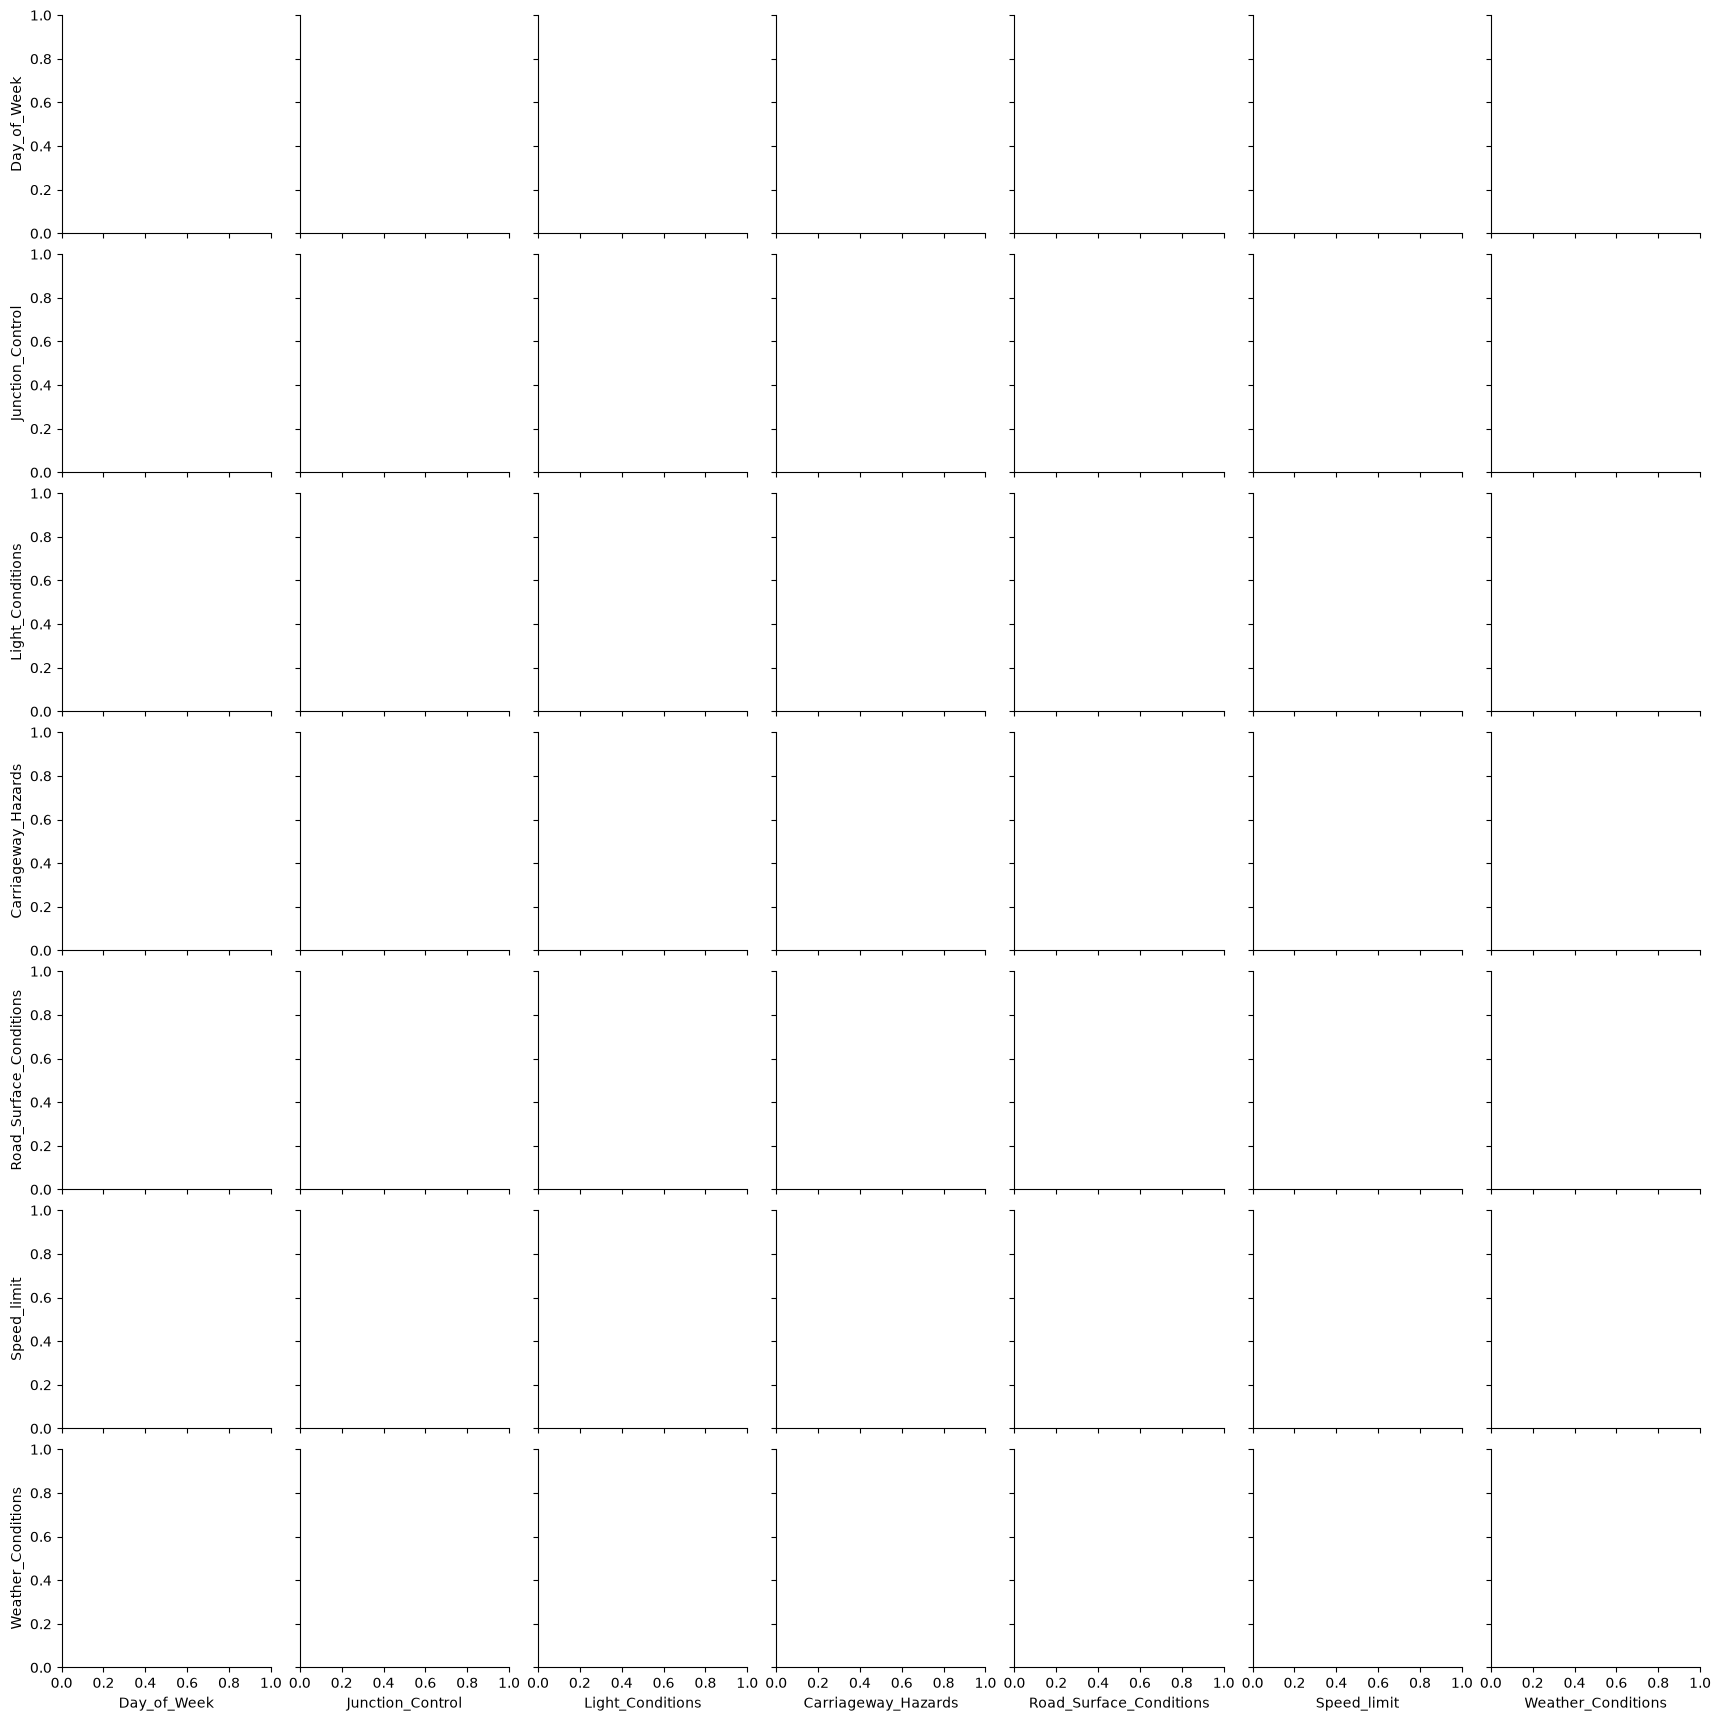

In [ ]:

cols = ["Day_of_Week", "Junction_Control", "Light_Conditions", "Carriageway_Hazards", "Road_Surface_Conditions", "Speed_limit", "Weather_Conditions"]

g = sns.pairplot(
    df,
    vars=cols,
    hue="Accident_Severity",
    plot_kws={"alpha": 0.5},  # Transparenz gegen Überlagerung
)
plt.show()